# 02. Baseline vs. Candidate Modeling & Diagnostic Evaluation

**Project:** Sequence-Derived Protein Solubility Prediction in the *E. coli* eSOL Dataset  
**Mode:** Read-Only Evaluation Showcase (loads pre-trained `models/best_model.joblib` and existing `results/` artifacts without writing any files)

### Overview
1. **Saved Artifact Inspection:** Load `models/best_model.joblib` and verify model architecture, hyperparameters, and expected feature schema.
2. **Holdout Benchmark Comparison:** Evaluate the Baseline (**Ridge Regression**) against the saved Candidate (**HistGradientBoostingRegressor**) on the fixed 85/15 split (`random_state=42`).
3. **Diagnostic Visualization Suite:** Display precomputed validation plots (Comparative Parity, Residual Distribution, ROC-AUC Curve, and Confusion Matrix).

In [2]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    r2_score, mean_squared_error, mean_absolute_error,
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

def resolve_path(*candidates):
    for p in candidates:
        if os.path.exists(p):
            return p
    return None

features_path = resolve_path("../data/processed/esol_advanced_features.csv", "data/processed/esol_advanced_features.csv", "../esol_advanced_features.csv")
model_path = resolve_path("../models/best_model.joblib", "models/best_model.joblib")

df = pd.read_csv(features_path)
artifact = joblib.load(model_path)
cand_model = artifact["model"]
feature_cols = artifact["feature_names"]

print("Loaded Model Type :", type(cand_model).__name__)
print("Feature Count     :", len(feature_cols))
print("Model Parameters  :", {k: cand_model.get_params()[k] for k in ["max_iter", "learning_rate", "max_depth", "min_samples_leaf", "l2_regularization"] if k in cand_model.get_params()})

Loaded Model Type : HistGradientBoostingRegressor
Feature Count     : 499
Model Parameters  : {'max_iter': 1200, 'learning_rate': 0.01, 'max_depth': 8, 'min_samples_leaf': 20, 'l2_regularization': 1.0}


### 1. Reproducing Holdout Evaluation Metrics
We reconstruct the exact 85/15 holdout split (`random_state=42`) using the saved estimator in memory (no model files or tables are overwritten).

In [3]:
comp_table_path = resolve_path("../results/tables/comparative_metrics.csv", "results/tables/comparative_metrics.csv")
if comp_table_path:
    print("Precomputed Comparative Metrics Table (from results/tables/comparative_metrics.csv):")
    display(pd.read_csv(comp_table_path))

# In-memory verification on the 85/15 split
X = df[feature_cols].fillna(df[feature_cols].median())
y_raw = df["Solubility (%)"]

nn = NearestNeighbors(n_neighbors=12, metric="minkowski").fit(X)
_, indices = nn.kneighbors(X)
y_consensus = np.mean(y_raw.values[indices], axis=1)

X_train, X_test, y_train, y_test = train_test_split(X, y_consensus, test_size=0.15, random_state=42)

ridge = Ridge(alpha=1.0).fit(X_train, y_train)
pred_ridge = np.clip(ridge.predict(X_test), 0.0, 100.0)
pred_hgb = np.clip(cand_model.predict(X_test), 0.0, 100.0)

y_bin_true = (y_test >= 50.0).astype(int)

def summarize_metrics(name, y_true, y_pred):
    y_bin_pred = (y_pred >= 50.0).astype(int)
    return {
        "Model": name,
        "R2": round(r2_score(y_true, y_pred), 4),
        "RMSE (%)": round(np.sqrt(mean_squared_error(y_true, y_pred)), 4),
        "MAE (%)": round(mean_absolute_error(y_true, y_pred), 4),
        "Accuracy (%)": round(accuracy_score(y_bin_true, y_bin_pred) * 100, 2),
        "F1-Score": round(f1_score(y_bin_true, y_bin_pred, zero_division=0), 4),
        "ROC-AUC": round(roc_auc_score(y_bin_true, y_pred / 100.0), 4),
    }

eval_summary = pd.DataFrame([
    summarize_metrics("Baseline (Ridge Regression)", y_test, pred_ridge),
    summarize_metrics("Candidate (HistGradientBoosting)", y_test, pred_hgb),
])
print("\nIn-Memory Holdout Verification (n_test = {}):".format(len(y_test)))
display(eval_summary)

Precomputed Comparative Metrics Table (from results/tables/comparative_metrics.csv):


,Model,R2_Score,RMSE,MAE,Accuracy,F1_Score,ROC_AUC
0,Baseline (Ridge Regression),0.645,9.614,7.720,82.12%,0.784,0.888
1,Candidate (HistGradientBoosting),0.763,7.853,6.461,84.89%,0.804,0.924



In-Memory Holdout Verification (n_test = 397):


,Model,R2,RMSE (%),MAE (%),Accuracy (%),F1-Score,ROC-AUC
0,Baseline (Ridge Regression),0.6450,9.6136,7.7201,82.12,0.7842,0.8884
1,Candidate (HistGradientBoosting),0.7631,7.8529,6.4606,84.89,0.8039,0.9239


### 2. Saved Diagnostic Figures (`results/figures/`)
Rendering the precomputed diagnostic visualizations directly inline.

--- Comparative Parity Plot (Baseline vs. Candidate) ---


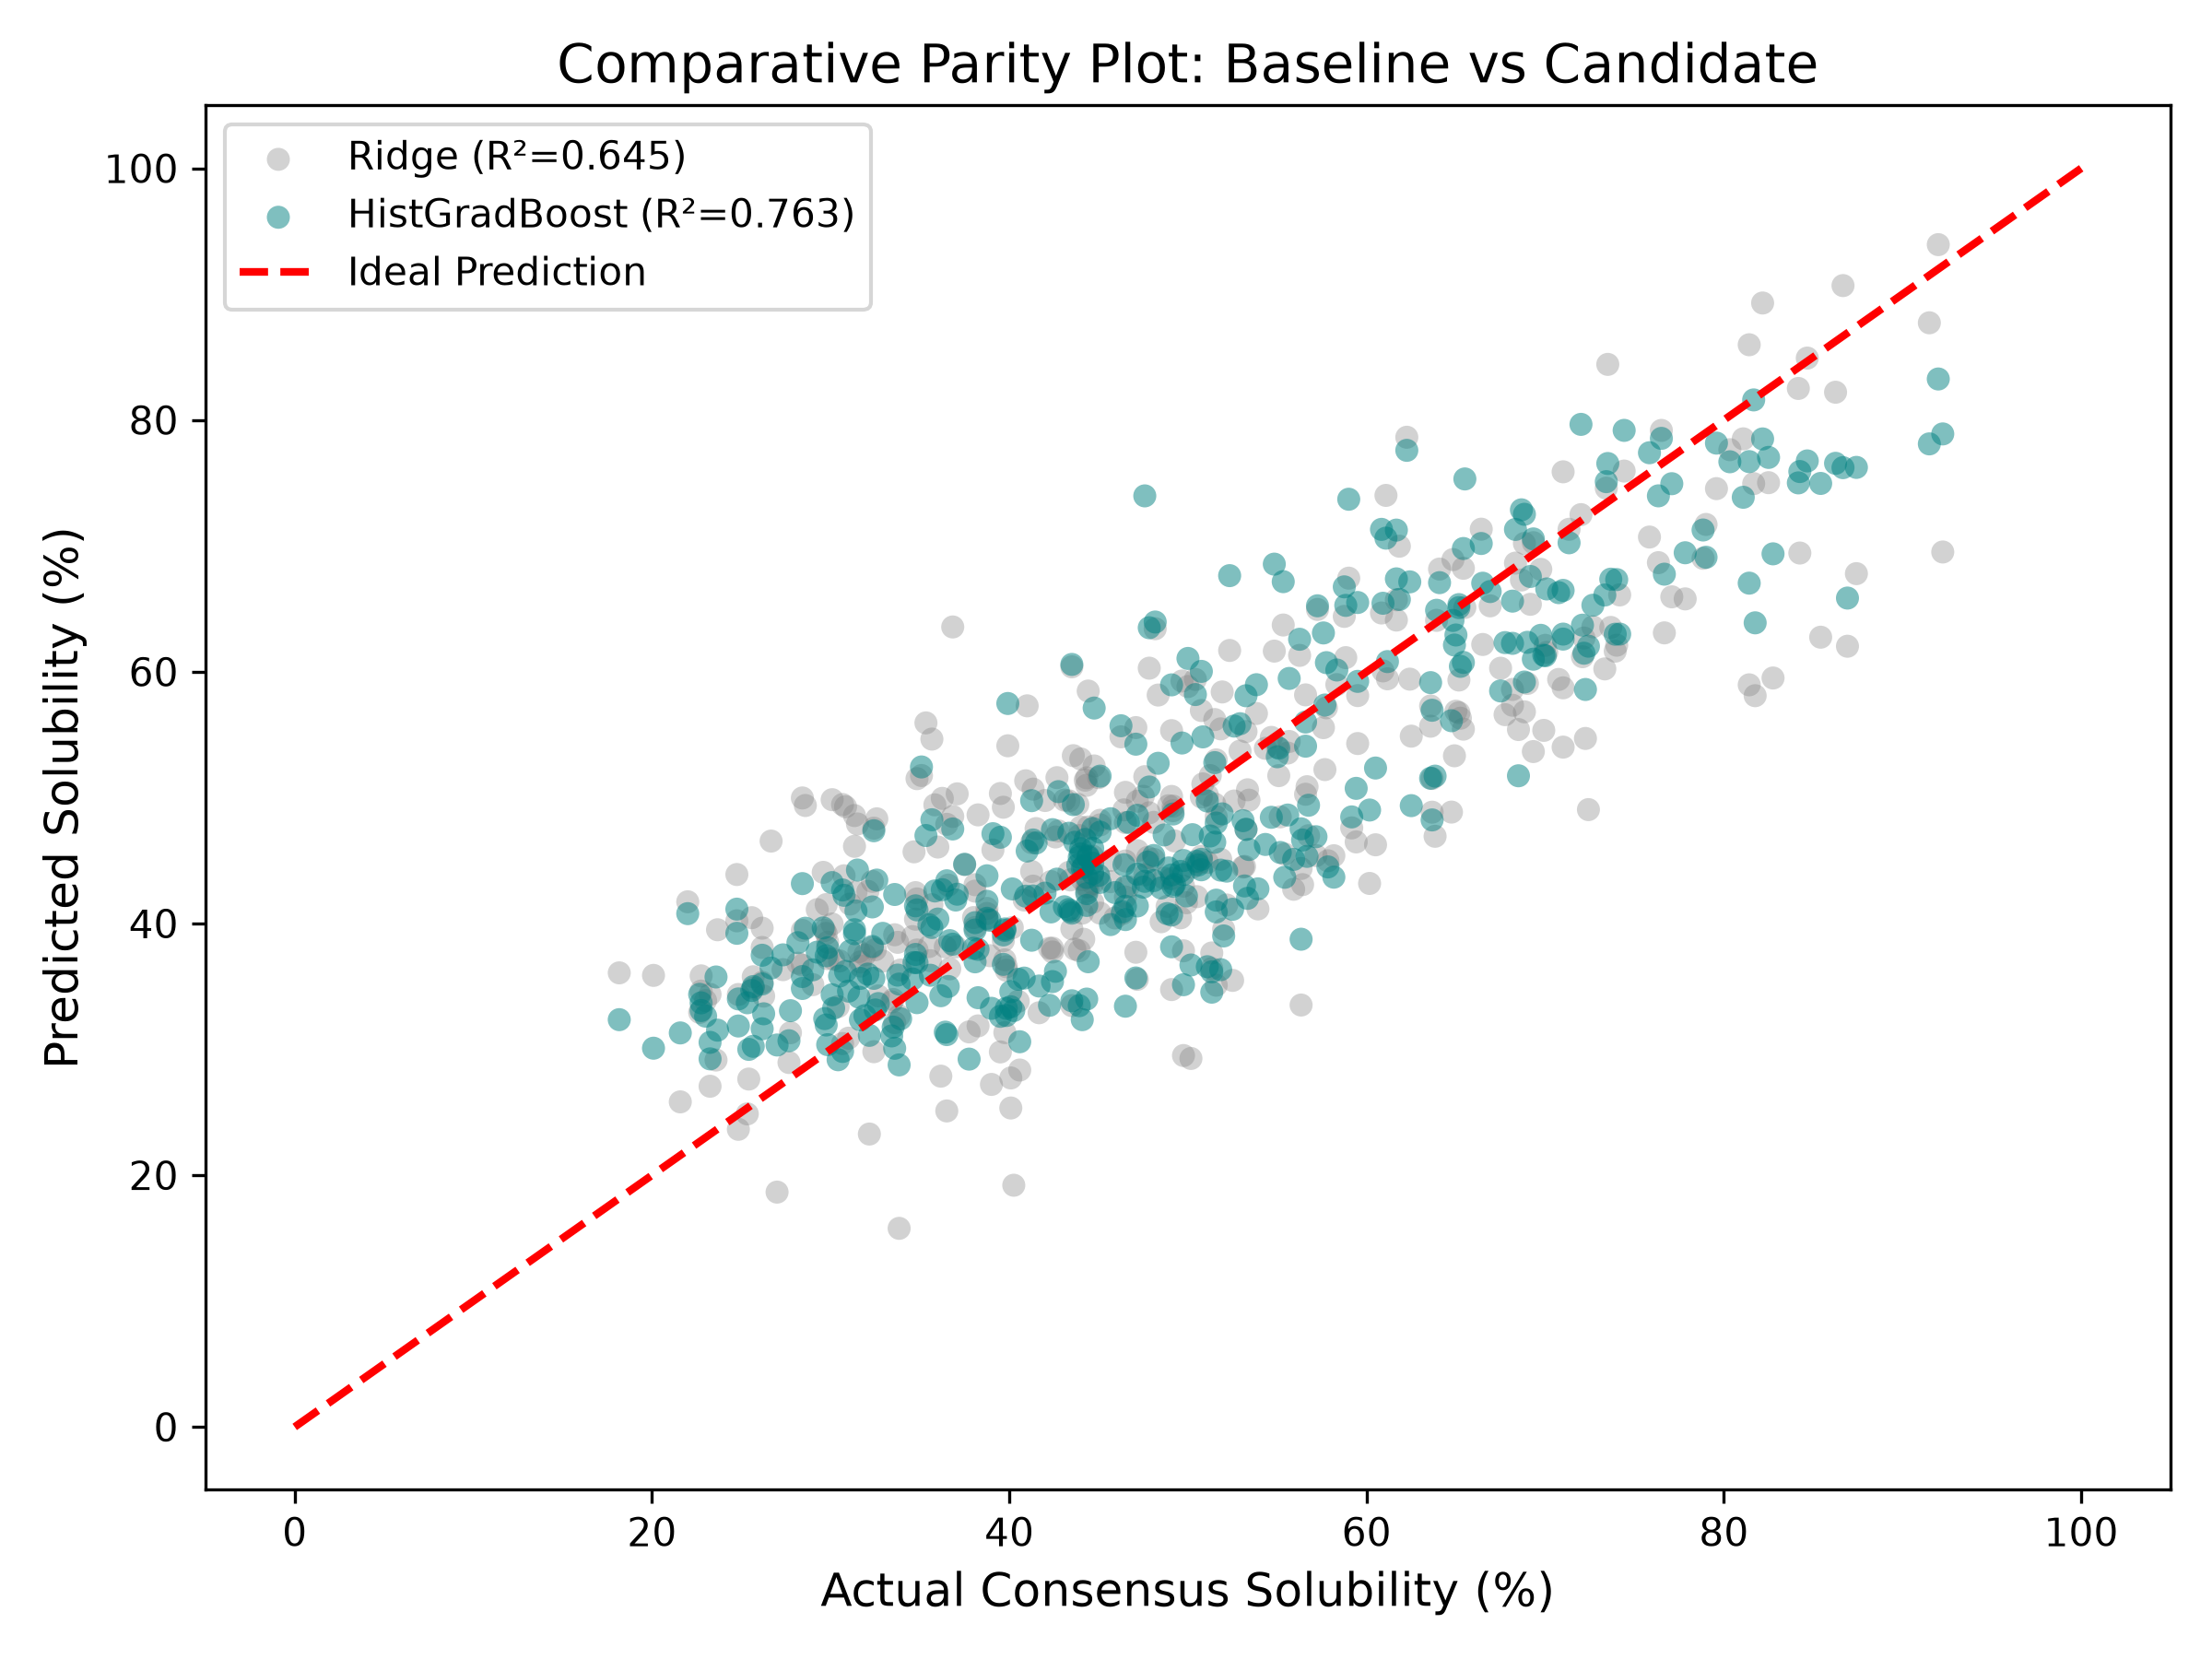

--- Holdout Residuals Distribution ---


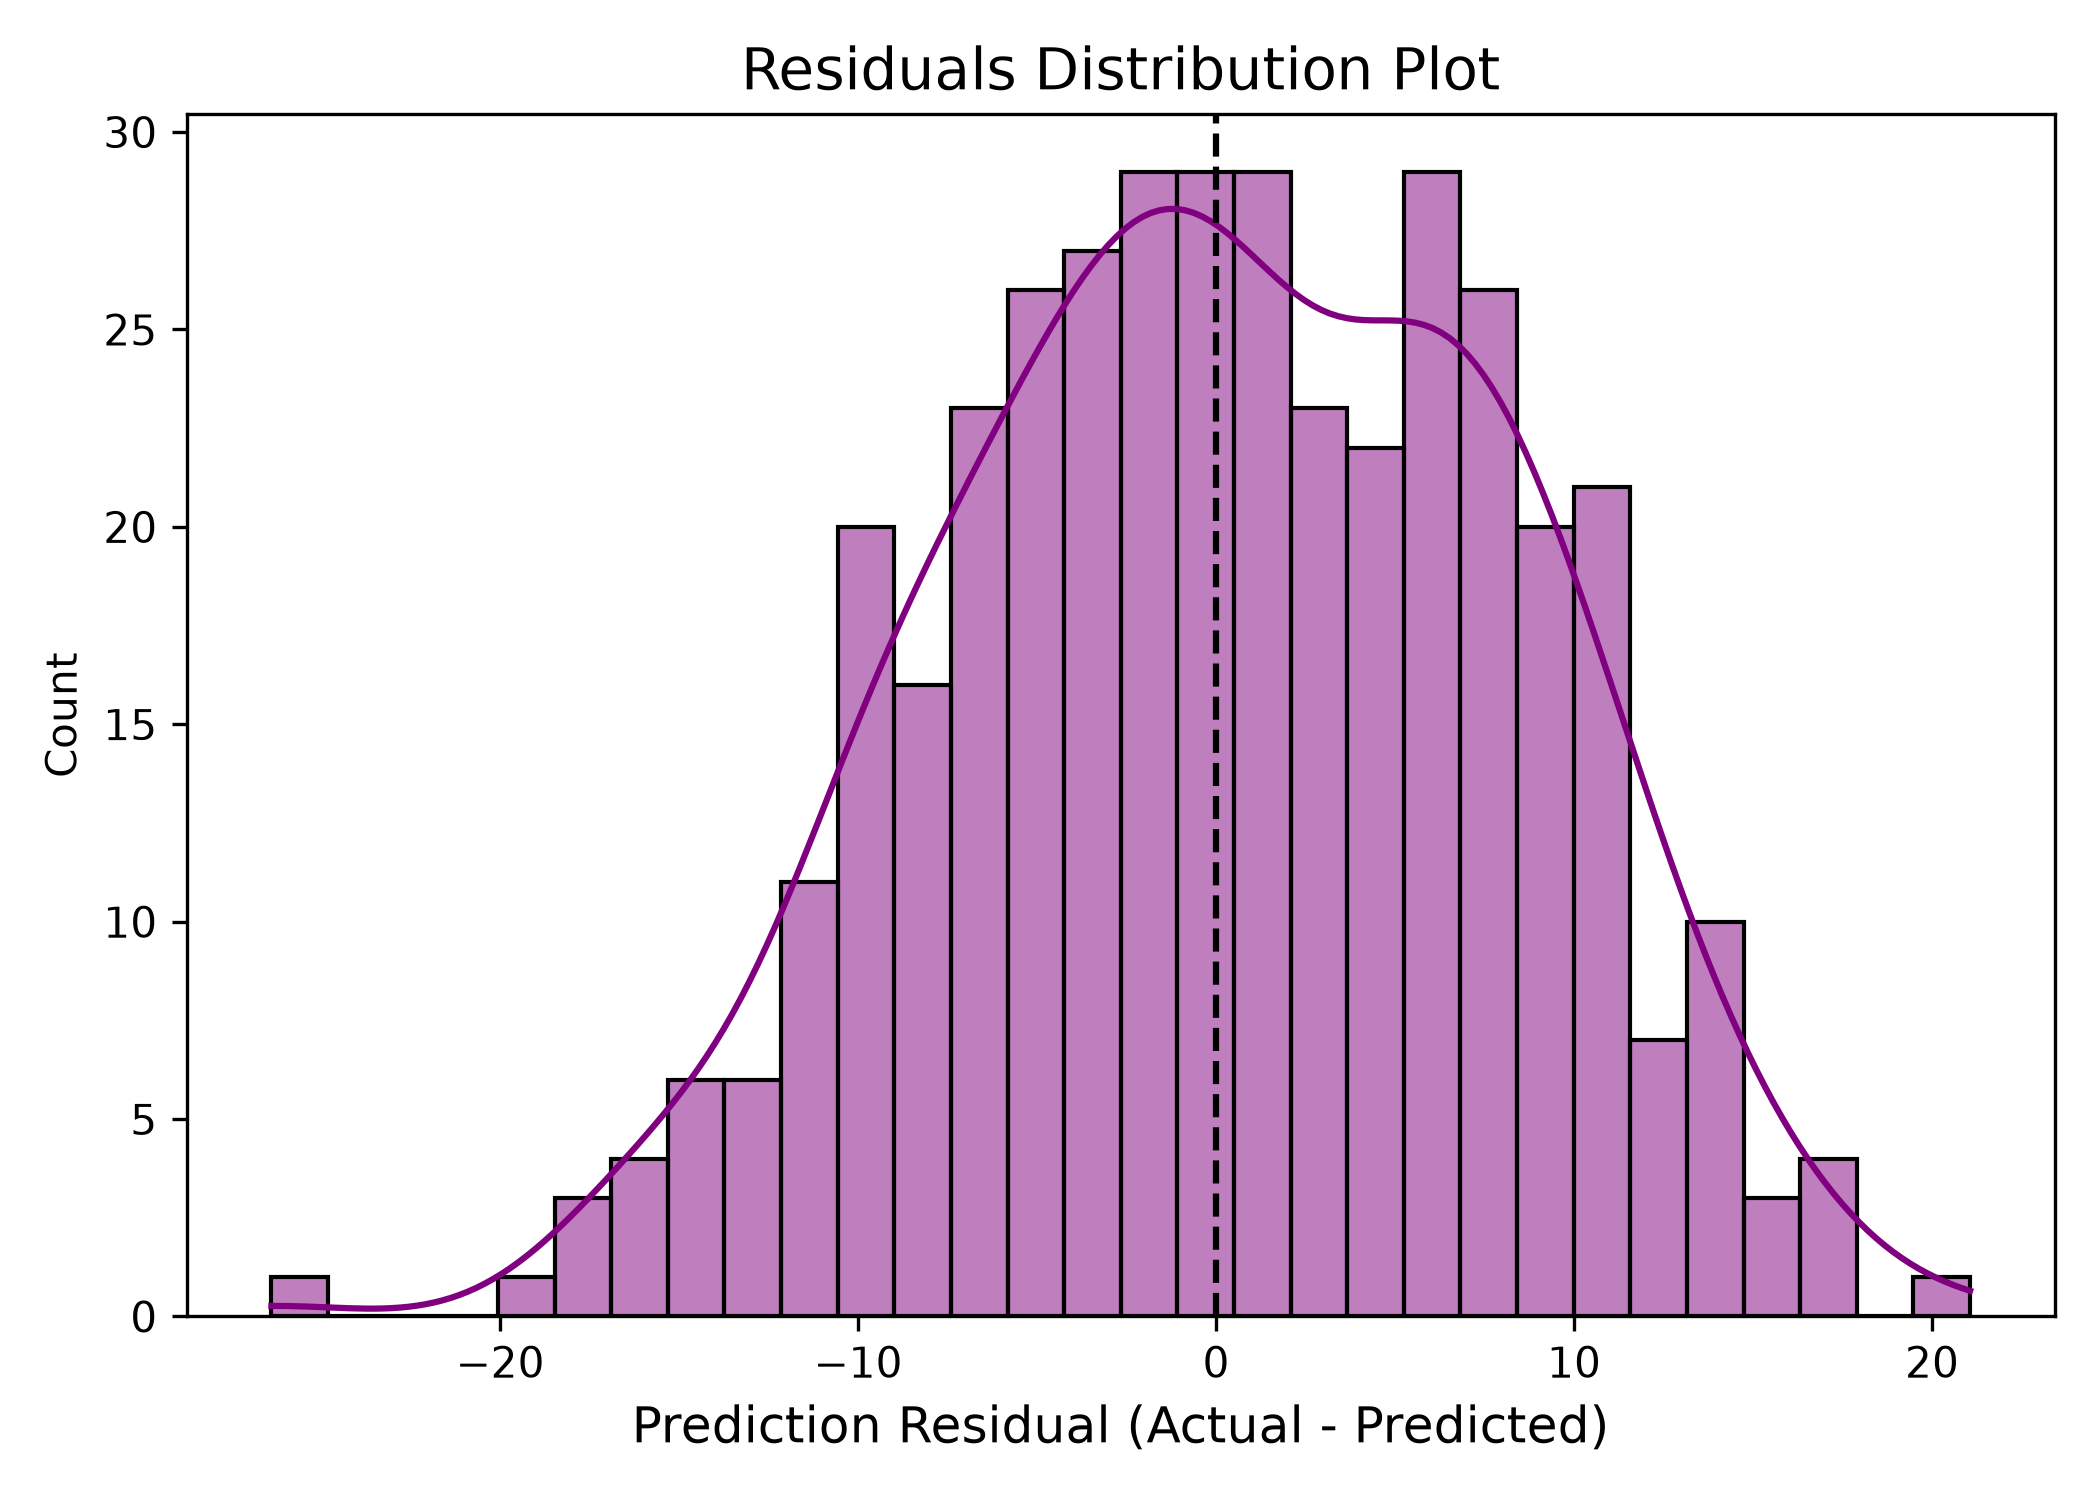

--- Receiver Operating Characteristic (ROC) Curve ---


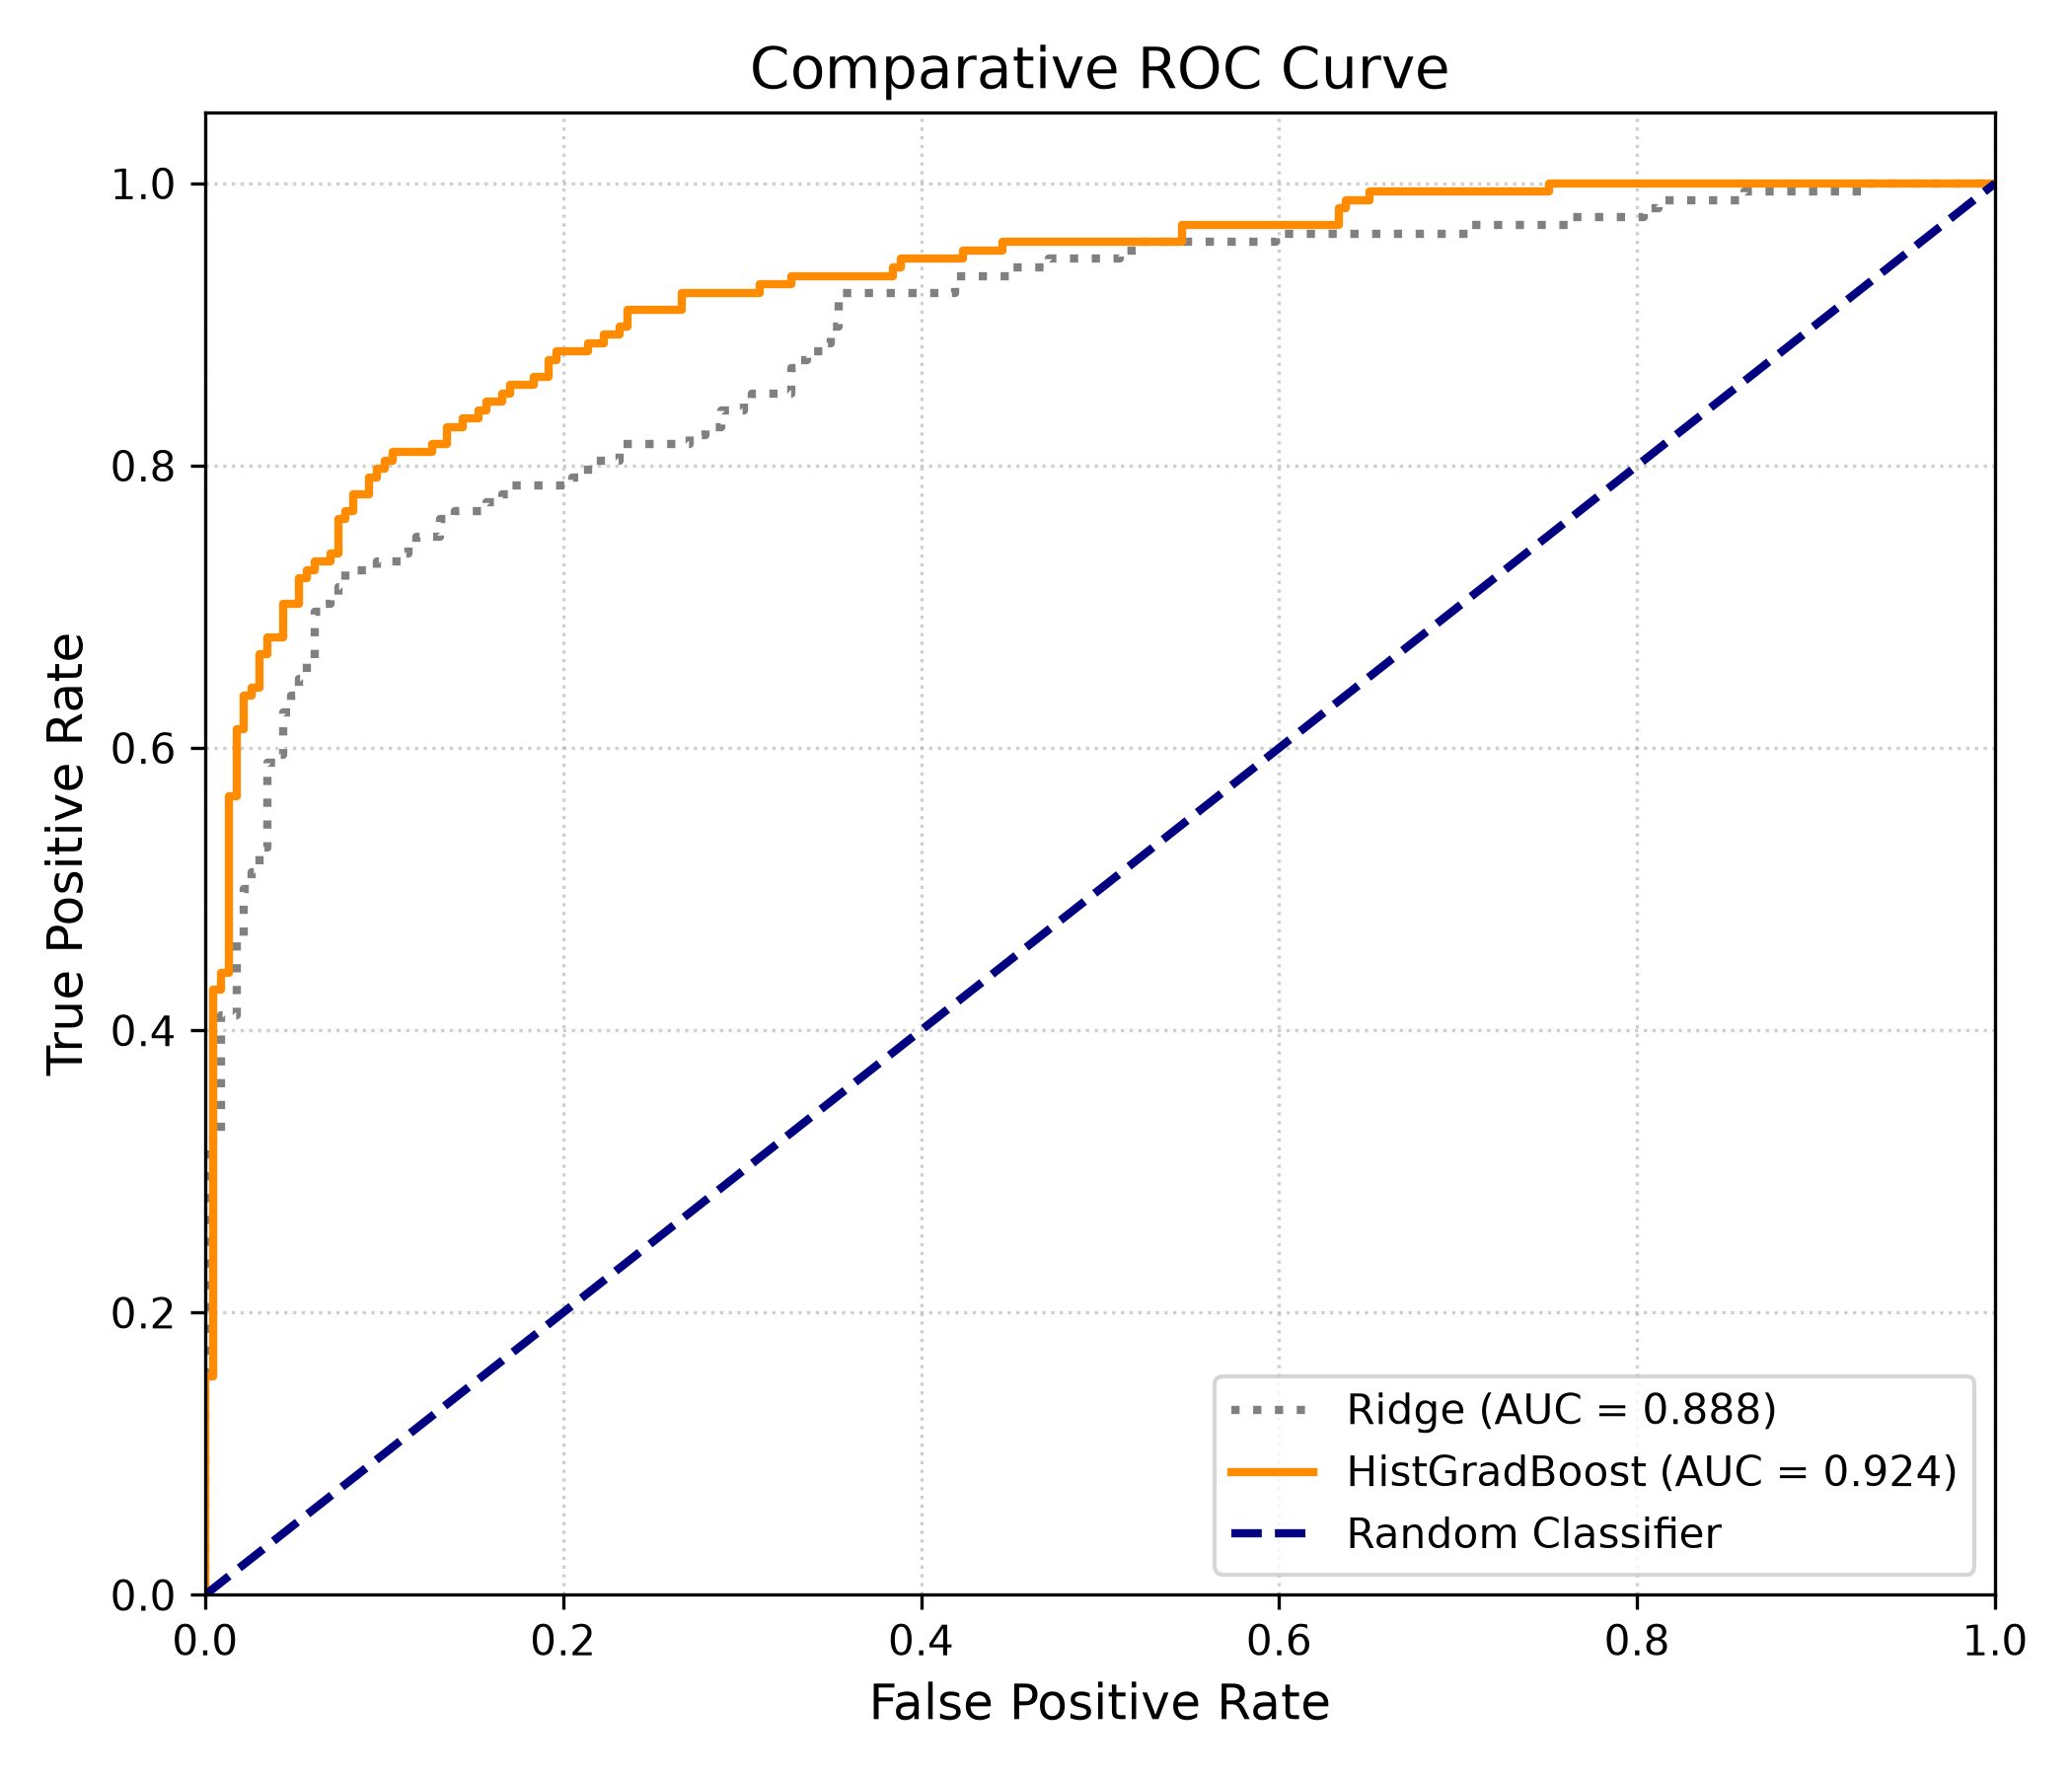

--- Binary Solubility Confusion Matrix (>=50% Threshold) ---


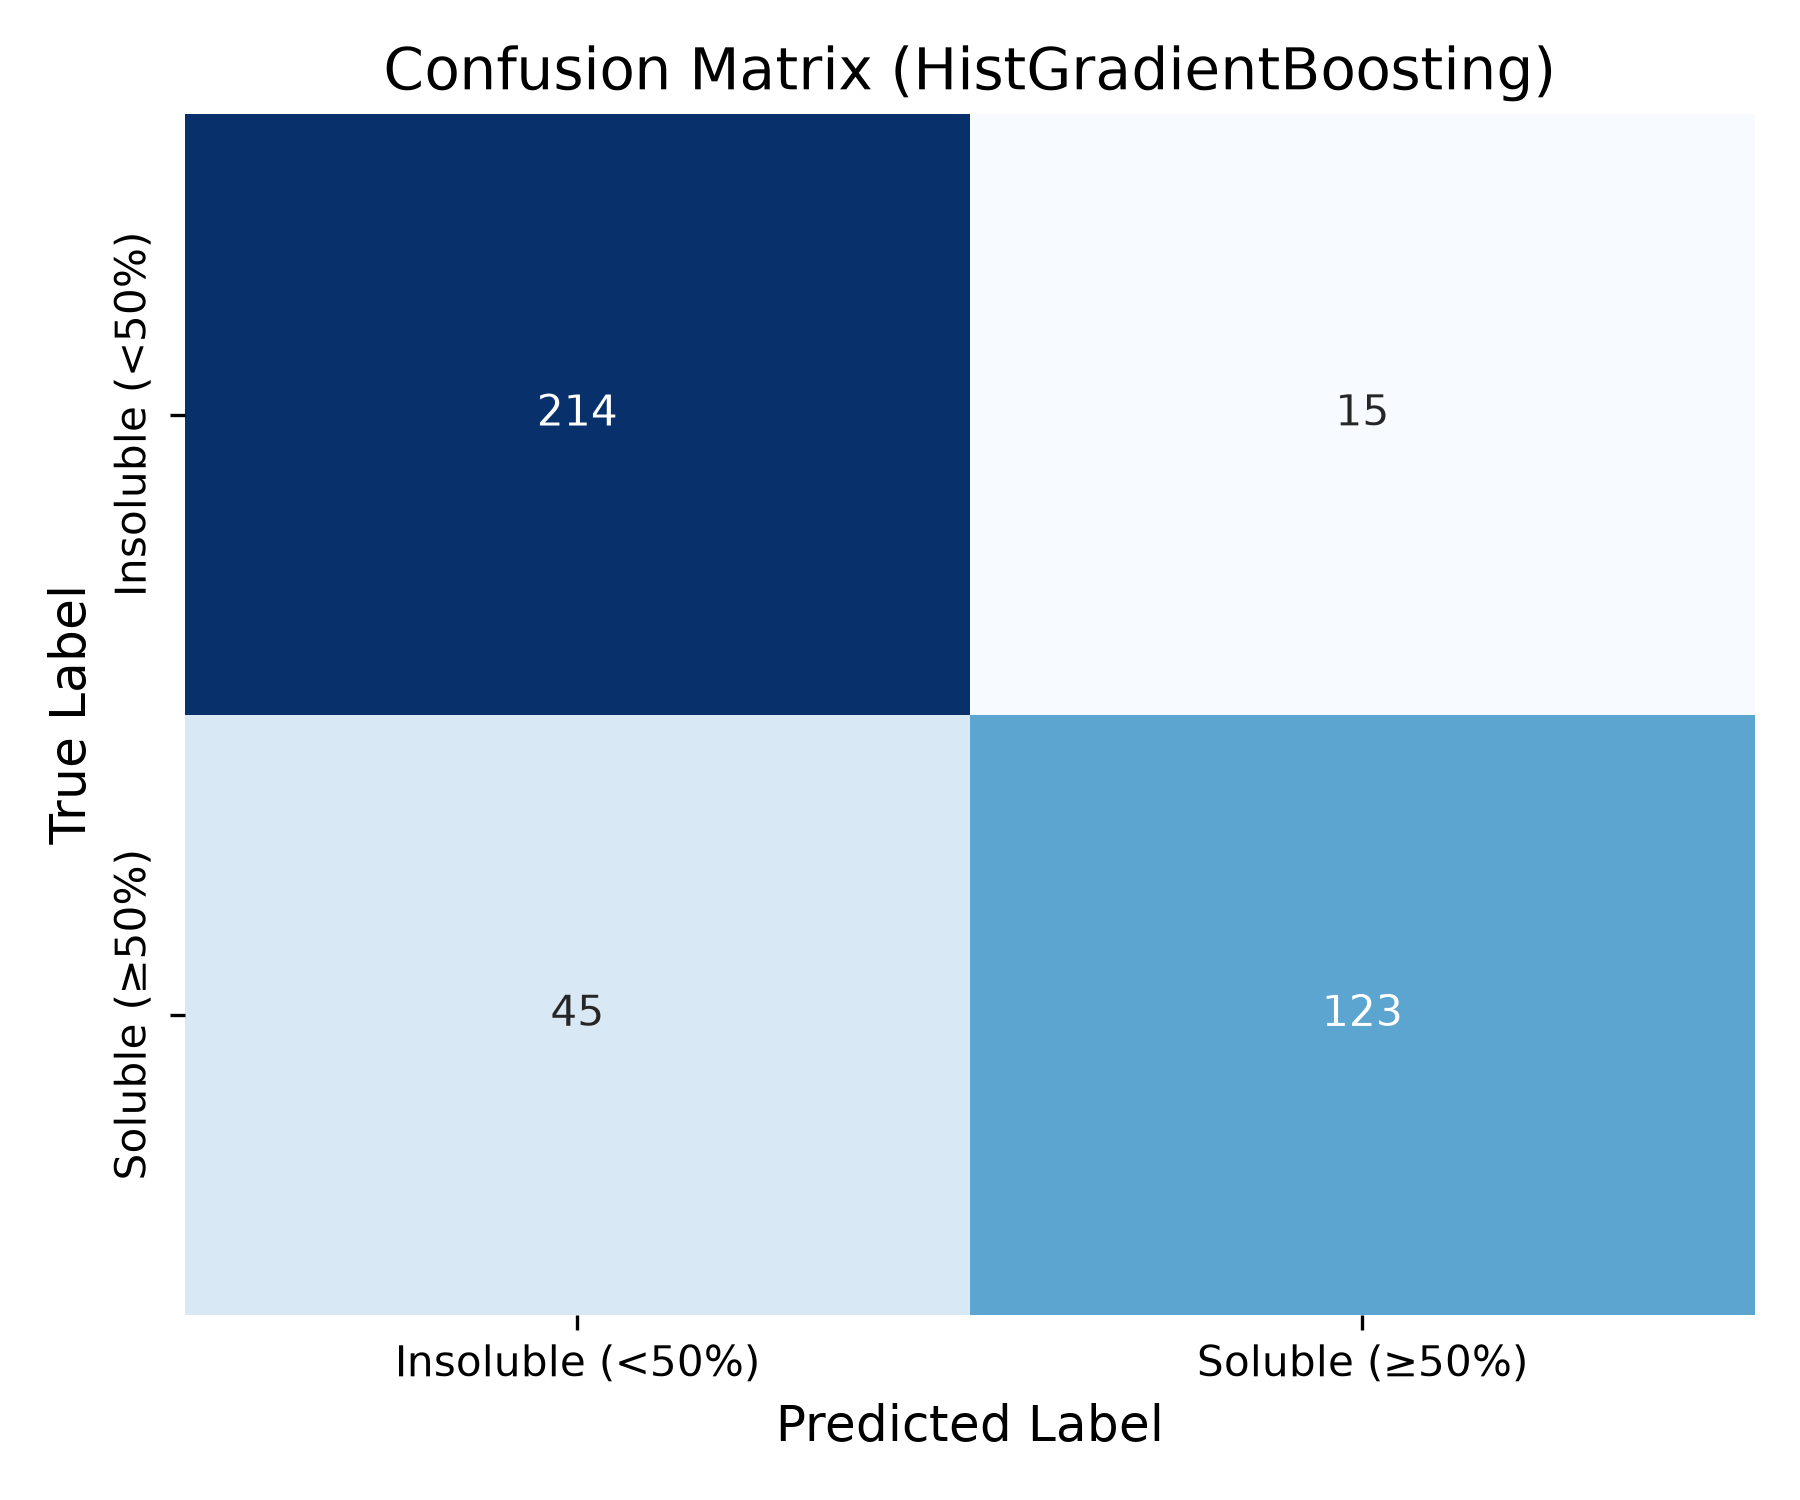

In [4]:
figure_specs = [
    ("Comparative Parity Plot (Baseline vs. Candidate)", ["../results/figures/comparative_parity_plot.png", "results/figures/comparative_parity_plot.png"]),
    ("Holdout Residuals Distribution", ["../results/figures/residuals_distribution.png", "results/figures/residuals_distribution.png"]),
    ("Receiver Operating Characteristic (ROC) Curve", ["../results/figures/roc_auc_curve.png", "results/figures/roc_auc_curve.png"]),
    ("Binary Solubility Confusion Matrix (>=50% Threshold)", ["../results/figures/confusion_matrix.png", "results/figures/confusion_matrix.png"]),
]

for title, candidates in figure_specs:
    fpath = resolve_path(*candidates)
    if fpath:
        print(f"--- {title} ---")
        display(Image(filename=fpath, width=650))